Investigate our data_raw

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import solarpy
import pvlib
import pandas as pd

In [32]:
from pathlib import Path
import sys

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from scripts.functions import prep_dmi_irradiance

In [33]:
data_raw = prep_dmi_irradiance(start="2025-01-01", end="2025-12-31")

data_raw.head(20)

parameterId,ghi
timestamp,
2025-01-01 00:00:00+00:00,0.0
2025-01-01 00:10:00+00:00,0.0
2025-01-01 00:20:00+00:00,0.0
2025-01-01 00:30:00+00:00,0.0
2025-01-01 00:40:00+00:00,0.0
2025-01-01 01:00:00+00:00,0.0
2025-01-01 01:10:00+00:00,0.0
2025-01-01 01:20:00+00:00,0.0
2025-01-01 01:30:00+00:00,0.0


In [34]:
data_raw.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 52226 entries, 2025-01-01 00:00:00+00:00 to 2025-12-31 00:00:00+00:00
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ghi     52226 non-null  float64
dtypes: float64(1)
memory usage: 816.0 KB


In [35]:
data_raw.describe()

parameterId,ghi
count,52226.000000
mean,125.786045
std,213.845779
min,0.000000
25%,0.000000
50%,3.000000
75%,160.000000
max,1180.000000


Sørg for at for bsrn data check skal tidsstemplet tages for solpositionen efter 5 min for at være mere repræsentativt

In [36]:
measurement_midpoints = data_raw.index - pd.Timedelta(minutes=5)

solpos = pvlib.solarposition.get_solarposition(
    measurement_midpoints,
    latitude=56.93,
    longitude=8.6412,
    method="nrel_numpy",
)

data_raw["solar_zenith"] = solpos["zenith"].to_numpy()

### BSRN limits 

In [37]:
# write your code here

data_raw['dni_extra'] = pvlib.irradiance.get_extra_radiation(data_raw.index)


data_raw['ghi_extra'] = data_raw['dni_extra'] * np.cos(np.radians(data_raw['solar_zenith'])).clip(lower=0)


# calculate flag limits for ghi using the BSRN limits
data_raw["ghi_ppl_flag"] = solarpy.quality.bsrn_limits_flag(
    data_raw["ghi"],
    data_raw["solar_zenith"],
    data_raw["dni_extra"],
    limits="ghi-ppl",
    check="upper",
)

data_raw["ghi_erl_flag"] = solarpy.quality.bsrn_limits_flag(
    data_raw["ghi"],
    data_raw["solar_zenith"],
    data_raw["dni_extra"],
    limits="ghi-erl",
    check="upper",
)

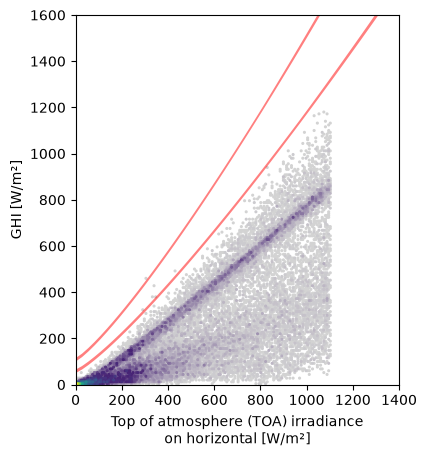

In [38]:
# plot the data and the BSRN limits
fig, ax = solarpy.plotting.plot_bsrn_limits(
    irradiance=data_raw["ghi"],
    component="ghi",
    ghi_extra=data_raw["ghi_extra"],
)

plt.show()

In [39]:
_, data_raw["ghi_ppl_upper"] = solarpy.quality.bsrn_limits(
    data_raw["solar_zenith"], data_raw["dni_extra"], limits="ghi-ppl"
)

_, data_raw["ghi_erl_upper"] = solarpy.quality.bsrn_limits(
    data_raw["solar_zenith"], data_raw["dni_extra"], limits="ghi-erl"
)

# Over ERL, men stadig inden for PPL
erl_only = data_raw.loc[
    (data_raw["ghi"] > data_raw["ghi_erl_upper"])
    & (data_raw["ghi"] <= data_raw["ghi_ppl_upper"]),
    ["ghi", "ghi_erl_upper", "ghi_ppl_upper", "solar_zenith"],
]

# Over PPL: uden for den fysisk mulige grænse
above_ppl = data_raw.loc[
    data_raw["ghi"] > data_raw["ghi_ppl_upper"],
    ["ghi", "ghi_ppl_upper", "ghi_erl_upper", "solar_zenith"],
]

print("Over ERL, men inden for PPL:", len(erl_only))
print("Over PPL:", len(above_ppl))

display(erl_only)
display(above_ppl)

Over ERL, men inden for PPL: 5
Over PPL: 1


parameterId,ghi,ghi_erl_upper,ghi_ppl_upper,solar_zenith
timestamp,,,,
2025-05-03 05:40:00+00:00,383.0,365.126410,493.908012,75.133570
2025-10-04 14:20:00+00:00,493.0,460.981641,613.727051,71.586847
2025-11-16 10:30:00+00:00,383.0,345.938944,469.923680,76.373352
2025-11-16 11:10:00+00:00,427.0,360.730456,488.413070,75.796485
2025-11-19 12:30:00+00:00,327.0,302.985066,416.231333,78.082339


parameterId,ghi,ghi_ppl_upper,ghi_erl_upper,solar_zenith
timestamp,,,,
2025-11-19 10:20:00+00:00,457.0,438.065315,320.452252,77.389569


<Axes: xlabel='timestamp'>

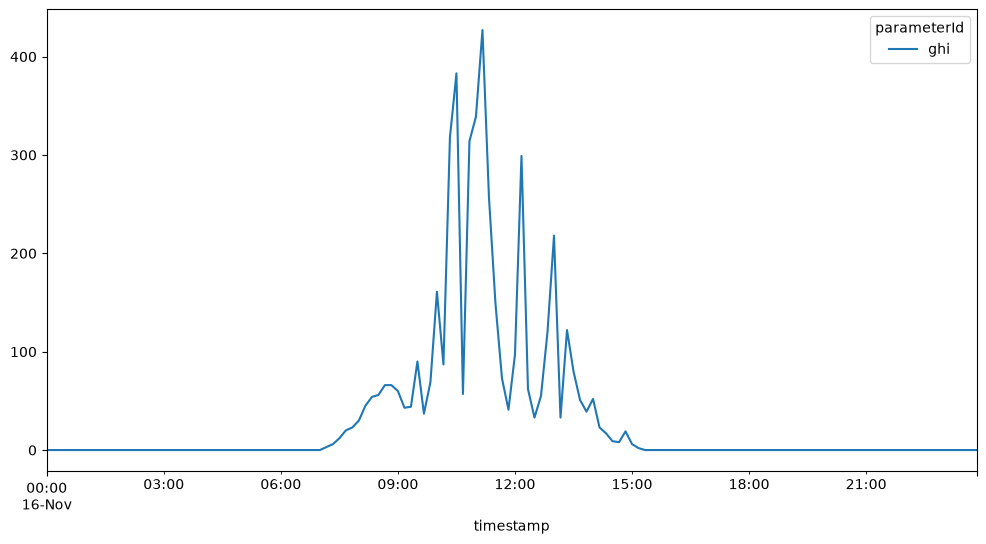

In [40]:
error_data = data_raw.loc["2025-11-16"]
# display(error_data)

error_data.plot(y=["ghi"], figsize=(12, 6))

Convert from 10 min resolution to 1 hour with righ closed columns

In [41]:
# Group each hour's 10-minute measurements into a right-labeled average.
data_hourly= data_raw[["ghi"]].resample(
        "1h",
        label="right",
        closed="right",
    ).mean()

<Axes: xlabel='timestamp'>

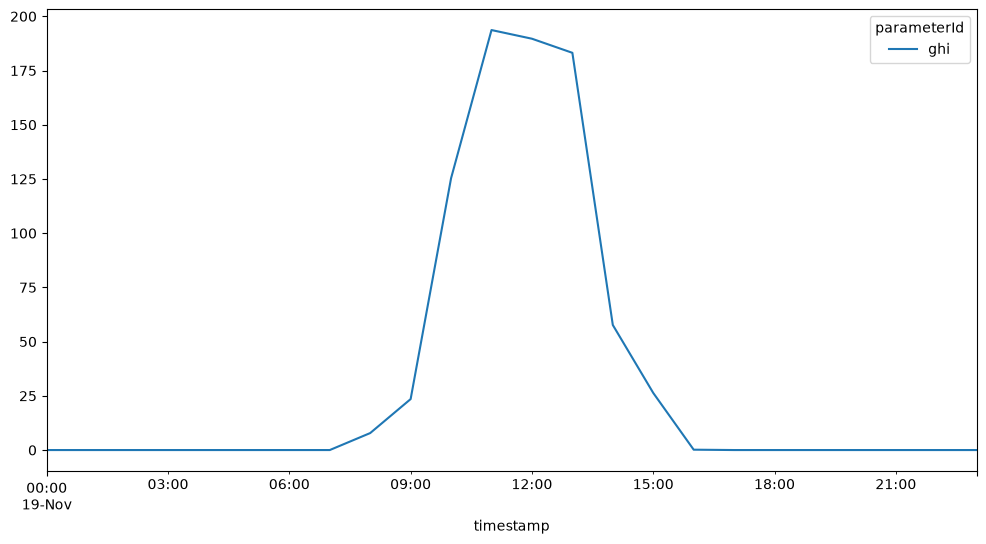

In [42]:
error_data1 = data_hourly.loc["2025-11-19"]
# display(error_data)

error_data1.plot(y=["ghi"], figsize=(12, 6))